In [1]:
import numpy as np
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
import matplotlib.pyplot as plt
from scipy import ndimage
from astropy.io import fits
import math
import glob, os
import stpsf
import time

In [2]:
# configure for coronagraphic calculation, and make a PSF centered on the coronagraph

h = 2.5
incl = 4.83544897

miri = stpsf.MIRI()
miri.filter='F1550C'
miri.image_mask='FQPM1550'
# Offset the source away from the mask
miri.options['source_offset_x'] = h*np.cos((45.-incl)*np.pi/180.)      # offset is in arcsec
miri.options['source_offset_y'] = h*np.cos((45.+incl)*np.pi/180.)      # offset is in arcsec
psf_source_offset = miri.calc_psf(nlambda=1, fov_pixels=400, add_distortion=False, oversample=2)


miri2 = stpsf.MIRI()
miri2.filter='F1550C'
miri2.image_mask='FQPM1550'
# Offset the source away from the mask
miri2.options['source_offset_x'] = h*np.cos((45.+incl)*np.pi/180.)      # offset is in arcsec
miri2.options['source_offset_y'] = h*np.cos((90.-incl)*np.pi/180.)     # offset is in arcsec
psf_source_offset2 = miri2.calc_psf(nlambda=1, fov_pixels=400, add_distortion=False, oversample=2)

miri0 = stpsf.MIRI()
miri0.filter='F1550C'
miri0.image_mask='FQPM1550'
# Offset the source away from the mask
miri0.options['source_offset_x'] = 0      # offset is in arcsec
miri0.options['source_offset_y'] = 0     # offset is in arcsec
psf_source_offset0 = miri0.calc_psf(nlambda=1, fov_pixels=400, add_distortion=False, oversample=2)

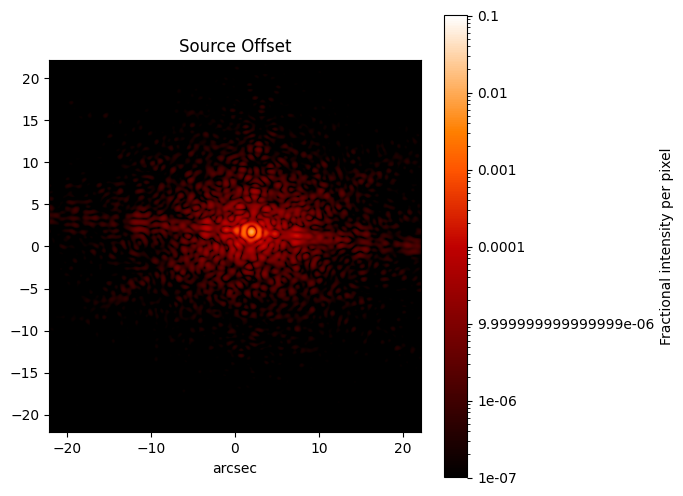

In [10]:
fig, axes = plt.subplots(figsize=(6,6), ncols=1)
stpsf.display_psf(psf_source_offset, ext=1, ax=axes, title=f'Source Offset', colorbar=True)

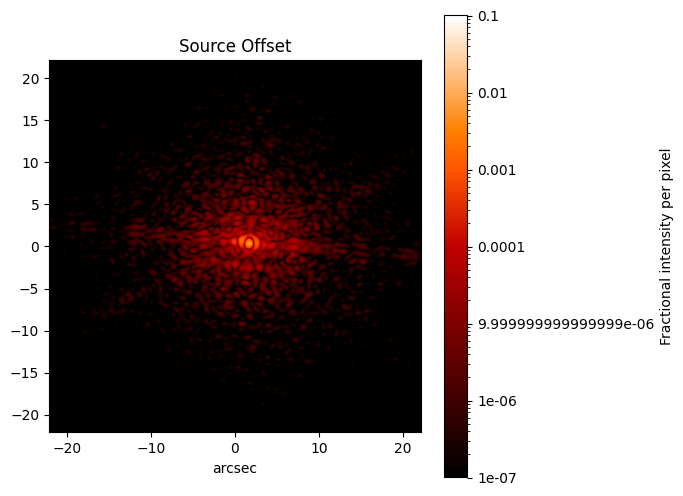

In [11]:
fig, axes = plt.subplots(figsize=(6,6), ncols=1)
stpsf.display_psf(psf_source_offset2, ext=1, ax=axes, title=f'Source Offset', colorbar=True)

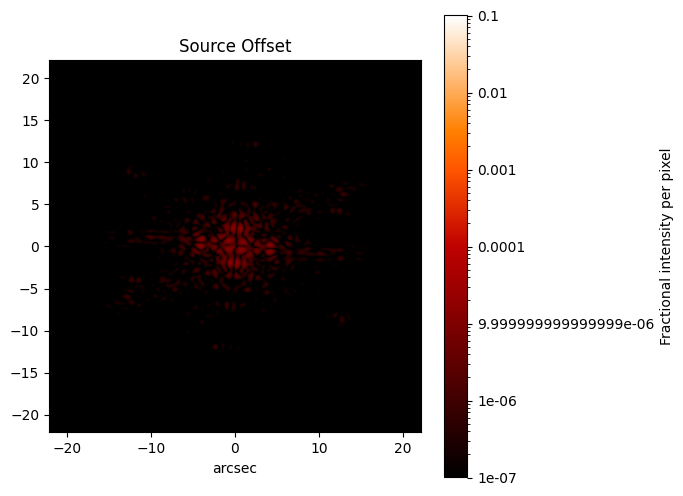

In [12]:
fig, axes = plt.subplots(figsize=(6,6), ncols=1)
stpsf.display_psf(psf_source_offset0, ext=1, ax=axes, title=f'Source Offset', colorbar=True)

In [48]:
psf_source_offset.info()

Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  OVERSAMP      1 PrimaryHDU     112   (400, 400)   float64   
  1  DET_SAMP      1 ImageHDU       114   (200, 200)   float64   


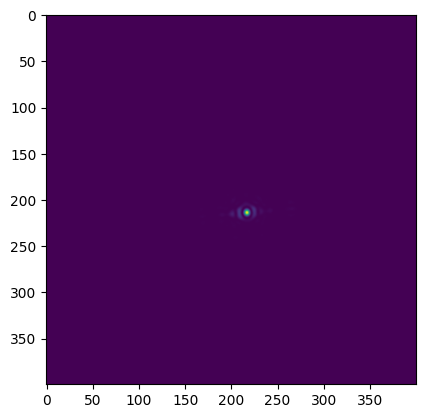

0.5845717890168468


In [14]:
plt.imshow(psf_source_offset['DET_SAMP'].data)
plt.show()
print(np.sum(psf_source_offset['DET_SAMP'].data))

In [15]:
savepath = "/home/cperrot/Work/raw/JWST/STPSF/F1550C_PSF/"
if not os.path.exists(savepath):
    os.makedirs(savepath)
    
imp.save_fits(psf_source_offset['DET_SAMP'].data,savepath+"F1550C_PSF_5500_5500mas.fits")
imp.save_fits(psf_source_offset2['DET_SAMP'].data,savepath+"F1550C_PSF_5500_-5500mas.fits")


In [2]:
## F1550C 
step  = 0.110 #arcsec
nstep = 201
dim   = 200
cube_save = np.ndarray([nstep*nstep,dim,dim])*0.
savepath = "/home/cperrot/Work/raw/JWST/STPSF/F1550C_PSF/"
if not os.path.exists(savepath):
    os.makedirs(savepath)

start=time.perf_counter()
for i in range(nstep):
    for j in range(nstep):
        miri = stpsf.MIRI()
        miri.filter='F1550C'
        miri.image_mask='FQPM1550'
        miri.pupil_mask = "MASKFQPM"
# Offset the source away from the mask
        miri.options['source_offset_x'] = (i-nstep//2)*step      # offset is in arcsec
        miri.options['source_offset_y'] = (j-nstep//2)*step      # offset is in arcsec
        psf_source_offset = miri.calc_psf(nlambda=1, fov_pixels=200, add_distortion=False, oversample=1)
        cube_save[i*nstep+j,:,:] = psf_source_offset['DET_SAMP'].data

end = time.perf_counter()
print(end-start)
print((end-start)/nstep**2)
imp.save_fits(cube_save,savepath+"F1550C_PSF_cube_save.fits")

miri = stpsf.MIRI()
miri.filter='F1550C'
miri.pupil_mask = "MASKFQPM"
psf_source_offset = miri.calc_psf(nlambda=1, fov_pixels=200, add_distortion=False, oversample=1)
imp.save_fits(psf_source_offset['DET_SAMP'].data,savepath+"F1550C_PSF_PSF_without_coro.fits")
print(np.sum(psf_source_offset['DET_SAMP'].data))


63363.43437933601
1.5683630202058367
0.582300536446985


In [3]:
## F1140C 
step  = 0.110 #arcsec
nstep = 201
dim   = 200
cube_save = np.ndarray([nstep*nstep,dim,dim])*0.
savepath = "/home/cperrot/Work/raw/JWST/STPSF/F1140C_PSF/"
if not os.path.exists(savepath):
    os.makedirs(savepath)

start=time.perf_counter()
for i in range(nstep):
    for j in range(nstep):
        miri = stpsf.MIRI()
        miri.filter='F1140C'
        miri.image_mask='FQPM1140'
        miri.pupil_mask = "MASKFQPM"
# Offset the source away from the mask
        miri.options['source_offset_x'] = (i-nstep//2)*step      # offset is in arcsec
        miri.options['source_offset_y'] = (j-nstep//2)*step      # offset is in arcsec
        psf_source_offset = miri.calc_psf(nlambda=1, fov_pixels=200, add_distortion=False, oversample=1)
        cube_save[i*nstep+j,:,:] = psf_source_offset['DET_SAMP'].data

end = time.perf_counter()
print(end-start)
print((end-start)/nstep**2)
imp.save_fits(cube_save,savepath+"F1140C_PSF_cube_save.fits")

miri = stpsf.MIRI()
miri.filter='F1140C'
miri.pupil_mask = "MASKFQPM"
psf_source_offset = miri.calc_psf(nlambda=1, fov_pixels=200, add_distortion=False, oversample=1)
imp.save_fits(psf_source_offset['DET_SAMP'].data,savepath+"F1140C_PSF_PSF_without_coro.fits")
print(np.sum(psf_source_offset['DET_SAMP'].data))


60741.44627814299
1.50346393104485
0.5889417125202523


In [4]:
## F1065C 
step  = 0.110 #arcsec
nstep = 201
dim   = 200
cube_save = np.ndarray([nstep*nstep,dim,dim])*0.
savepath = "/home/cperrot/Work/raw/JWST/STPSF/F1065C_PSF/"
if not os.path.exists(savepath):
    os.makedirs(savepath)

start=time.perf_counter()
for i in range(nstep):
    for j in range(nstep):
        miri = stpsf.MIRI()
        miri.filter='F1065C'
        miri.image_mask='FQPM1065'
        miri.pupil_mask = "MASKFQPM"
# Offset the source away from the mask
        miri.options['source_offset_x'] = (i-nstep//2)*step      # offset is in arcsec
        miri.options['source_offset_y'] = (j-nstep//2)*step      # offset is in arcsec
        psf_source_offset = miri.calc_psf(nlambda=1, fov_pixels=200, add_distortion=False, oversample=1)
        cube_save[i*nstep+j,:,:] = psf_source_offset['DET_SAMP'].data

end = time.perf_counter()
print(end-start)
print((end-start)/nstep**2)
imp.save_fits(cube_save,savepath+"F1065C_PSF_cube_save.fits")

miri = stpsf.MIRI()
miri.filter='F1065C'
miri.pupil_mask = "MASKFQPM"
psf_source_offset = miri.calc_psf(nlambda=1, fov_pixels=200, add_distortion=False, oversample=1)
imp.save_fits(psf_source_offset['DET_SAMP'].data,savepath+"F1065C_PSF_PSF_without_coro.fits")
print(np.sum(psf_source_offset['DET_SAMP'].data))

66190.276121509
1.6383326185368927
0.5899925384712645


In [50]:
(i-101//2)*0.11

-4.4

In [ ]:
psf_source_offset['DET_SAMP'].header['HISTORY']